# Análise de Resultados do Modelo

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

DATA_DIR = Path("../data")
df_val = pd.read_csv(DATA_DIR / "val_predictions_2.0.csv")
df_history = pd.read_csv(DATA_DIR / "training_history_2.0.csv")

df_val.head()

,y_true,y_prob,y_pred
0,1.0,0.990319,1.0
1,1.0,0.465945,0.0
2,0.0,0.306126,0.0
3,0.0,0.006403,0.0
4,1.0,0.636259,1.0


## 1. Métricas de Classificação (Conjunto de Validação)

In [2]:
y_true = df_val["y_true"]
y_pred = df_val["y_pred"]

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Acurácia:  {acc:.4f}")
print(f"Precisão:  {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("Relatório detalhado por classe:")
print(classification_report(y_true, y_pred, target_names=["Cat (0)", "Dog (1)"], digits=4))

Acurácia:  0.9326
Precisão:  0.9338
Recall:    0.9312
F1-Score:  0.9325

Relatório detalhado por classe:
              precision    recall  f1-score   support

     Cat (0)     0.9314    0.9340    0.9327      2500
     Dog (1)     0.9338    0.9312    0.9325      2500

    accuracy                         0.9326      5000
   macro avg     0.9326    0.9326    0.9326      5000
weighted avg     0.9326    0.9326    0.9326      5000



## 2. Matriz de Confusão

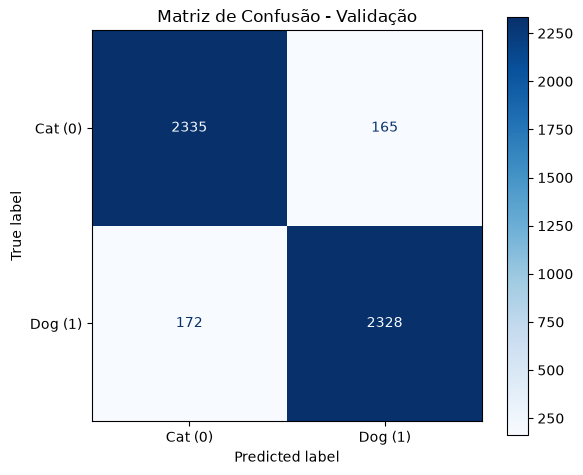

In [3]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cat (0)", "Dog (1)"])
disp.plot(cmap="Blues", values_format="d", ax=ax)
ax.set_title("Matriz de Confusão - Validação")
plt.tight_layout()
plt.show()

## 3. Histórico de Treinamento por Época

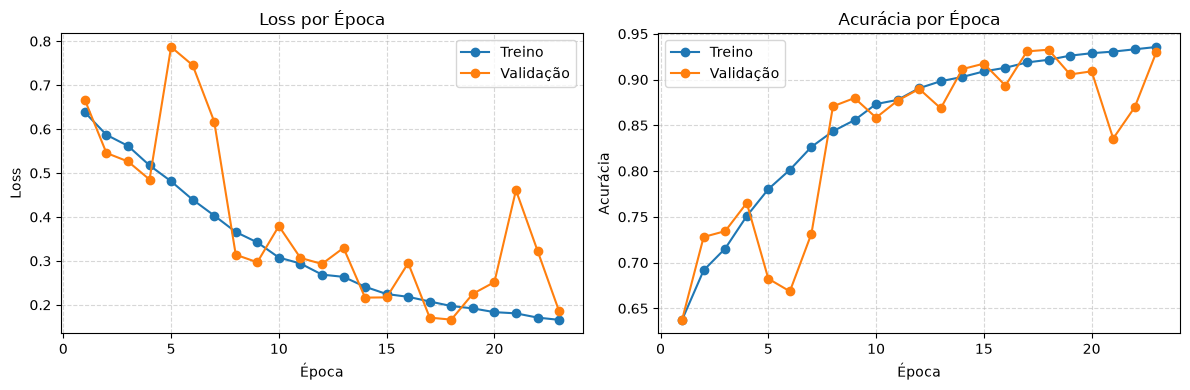

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(df_history["epoch"], df_history["train_loss"], marker="o", label="Treino")
axes[0].plot(df_history["epoch"], df_history["val_loss"], marker="o", label="Validação")
axes[0].set_title("Loss por Época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Acurácia
axes[1].plot(df_history["epoch"], df_history["train_acc"], marker="o", label="Treino")
axes[1].plot(df_history["epoch"], df_history["val_acc"], marker="o", label="Validação")
axes[1].set_title("Acurácia por Época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()